In [1]:
import pandas as pd
url = "https://raw.githubusercontent.com/AhmadaliyevB/DAtalar/refs/heads/main/automobile_data.csv"
df = pd.read_csv(url, na_values="?")
df.head()

,index,company,body-style,wheel-base,length,engine-type,num-of-cylinders,horsepower,average-mileage,price
0,0,alfa-romero,convertible,88.6,168.8,dohc,four,111,21,13495.0
1,1,alfa-romero,convertible,88.6,168.8,dohc,four,111,21,16500.0
2,2,alfa-romero,hatchback,94.5,171.2,ohcv,six,154,19,16500.0
3,3,audi,sedan,99.8,176.6,ohc,four,102,24,13950.0
4,4,audi,sedan,99.4,176.6,ohc,five,115,18,17450.0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 61 entries, 0 to 60
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   index             61 non-null     int64  
 1   company           61 non-null     str    
 2   body-style        61 non-null     str    
 3   wheel-base        61 non-null     float64
 4   length            61 non-null     float64
 5   engine-type       61 non-null     str    
 6   num-of-cylinders  61 non-null     str    
 7   horsepower        61 non-null     int64  
 8   average-mileage   61 non-null     int64  
 9   price             58 non-null     float64
dtypes: float64(3), int64(3), str(4)
memory usage: 4.9 KB


In [3]:
df.isnull().sum()

index               0
company             0
body-style          0
wheel-base          0
length              0
engine-type         0
num-of-cylinders    0
horsepower          0
average-mileage     0
price               3
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.describe()

,index,wheel-base,length,horsepower,average-mileage,price
count,61.000000,61.000000,61.000000,61.000000,61.000000,58.000000
mean,40.885246,98.481967,173.098361,107.852459,25.803279,15387.000000
std,25.429706,6.679234,14.021846,53.524398,8.129821,11320.259841
min,0.000000,88.400000,141.100000,48.000000,13.000000,5151.000000
25%,18.000000,94.500000,159.100000,68.000000,19.000000,6808.500000
50%,39.000000,96.300000,171.200000,100.000000,25.000000,11095.000000
75%,61.000000,101.200000,177.300000,123.000000,31.000000,18120.500000
max,88.000000,120.900000,208.100000,288.000000,47.000000,45400.000000


In [6]:
df["price"].describe()

count       58.000000
mean     15387.000000
std      11320.259841
min       5151.000000
25%       6808.500000
50%      11095.000000
75%      18120.500000
max      45400.000000
Name: price, dtype: float64

In [8]:
df["price"] = df["price"].fillna(df["price"].median())
df.isnull().sum()

index               0
company             0
body-style          0
wheel-base          0
length              0
engine-type         0
num-of-cylinders    0
horsepower          0
average-mileage     0
price               0
dtype: int64

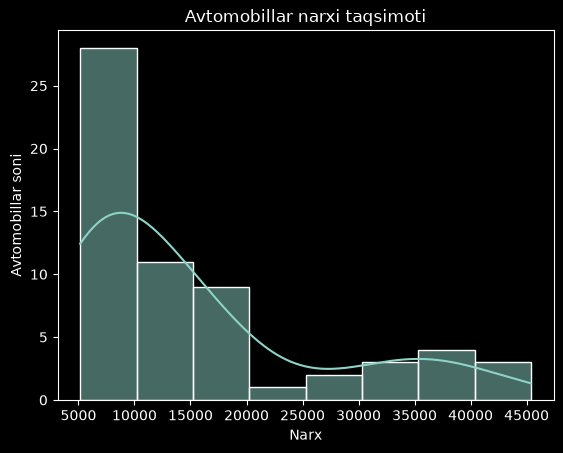

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.histplot(data=df, x="price", kde=True)
plt.title("Avtomobillar narxi taqsimoti")
plt.xlabel("Narx")
plt.ylabel("Avtomobillar soni")

plt.show()

In [12]:
df.columns

Index(['index', 'company', 'body-style', 'wheel-base', 'length', 'engine-type',
       'num-of-cylinders', 'horsepower', 'average-mileage', 'price'],
      dtype='str')

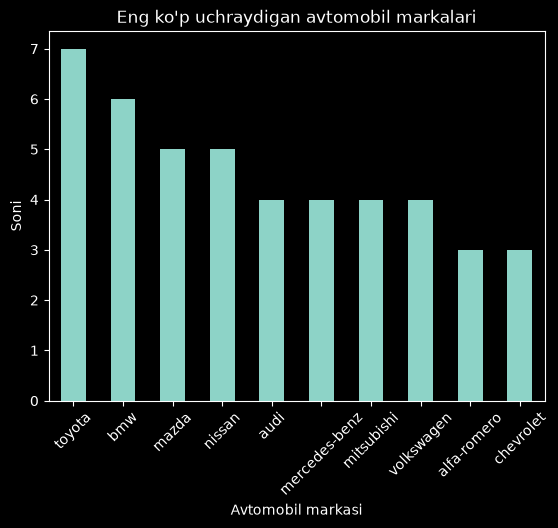

In [15]:
df["company"].value_counts().head(10).plot(kind="bar")
plt.title("Eng ko'p uchraydigan avtomobil markalari")
plt.xlabel("Avtomobil markasi")
plt.ylabel("Soni")
plt.xticks(rotation=45)
plt.show()

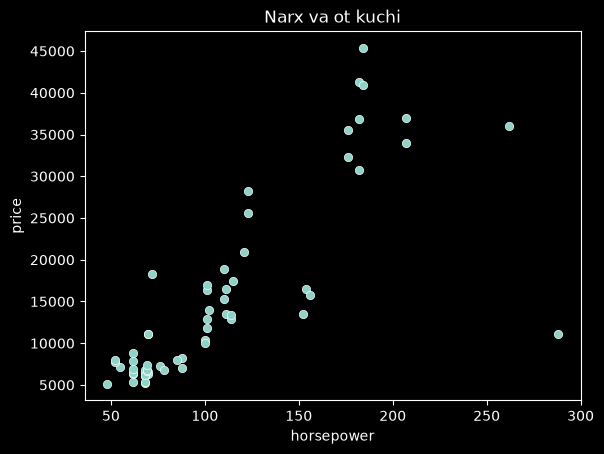

In [16]:
sns.scatterplot(data=df, x="horsepower", y="price")
plt.title("Narx va ot kuchi")
plt.show()

In [17]:
numeric_cols = df.select_dtypes(include="number").columns
numeric_cols

Index(['index', 'wheel-base', 'length', 'horsepower', 'average-mileage',
       'price'],
      dtype='str')

In [23]:
numeric_cols = [col for col in numeric_cols if col != 'index']
from sklearn.preprocessing import StandardScaler
df_scaled = df.copy()
scaler = StandardScaler()
df_scaled[numeric_cols] = scaler.fit_transform(df[numeric_cols])
df_scaled.head()

,company,body-style,wheel-base,length,engine-type,num-of-cylinders,horsepower,average-mileage,price
0,alfa-romero,convertible,-1.491784,-0.309091,dohc,four,0.059294,-0.595725,-0.153060
1,alfa-romero,convertible,-1.491784,-0.309091,dohc,four,0.059294,-0.595725,0.120567
2,alfa-romero,hatchback,-0.601119,-0.136509,ohcv,six,0.869333,-0.843775,0.120567
3,audi,sedan,0.198971,0.251800,ohc,four,-0.110249,-0.223651,-0.111629
4,audi,sedan,0.138586,0.251800,ohc,five,0.134646,-0.967800,0.207072


In [19]:
df = df.drop(columns=['index'], errors='ignore')

In [22]:
print(df.columns)

Index(['company', 'body-style', 'wheel-base', 'length', 'engine-type',
       'num-of-cylinders', 'horsepower', 'average-mileage', 'price'],
      dtype='str')


In [ ]:
df.to_csv("automobile_cleaned.csv", index=False)